# Neural Networks and Deep Learning — Lecture 5: Recurrent networks: RNN, LSTM and GRU for sequences and financial time series
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L5_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Returns, volatility and memory

In [3]:
import torch, torch.nn as nn
torch.set_num_threads(4)
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
def ohlc(tk):
    d = x[x.ticker == tk].set_index('date')[['open', 'high', 'low', 'close', 'adjclose']].dropna()
    end = (d.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
    d = d.loc[:end]; d = d[d.high > d.low]
    gk = 0.5 * np.log(d.high / d.low) ** 2 - (2 * np.log(2) - 1) * np.log(d.close / d.open) ** 2
    d['y'] = np.log(gk.clip(lower=1e-8)); d['r'] = 100 * np.log(d.adjclose).diff()
    return d.dropna()
spx = ohlc('SP500')
TR_END, VA_END = pd.Timestamp('2016-12-31'), pd.Timestamp('2019-12-31')
print(spx.index.min().date(), spx.index.max().date(), len(spx))

2005-01-04 2026-10-30 5491


rho_r(1) = -0.119  rho_|r|(1) = 0.315  rho_|r|(50) = 0.126


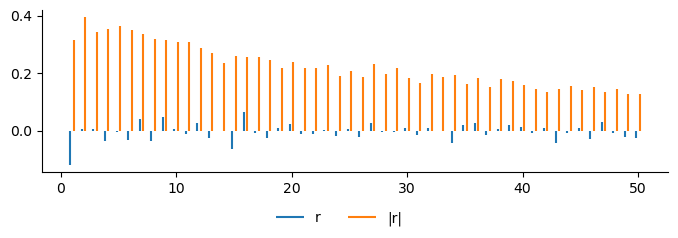

In [4]:
from statsmodels.tsa.stattools import acf
ar, aa = acf(spx.r, nlags=50, fft=True)[1:], acf(spx.r.abs(), nlags=50, fft=True)[1:]
print('rho_r(1) =', round(ar[0], 3), ' rho_|r|(1) =', round(aa[0], 3), ' rho_|r|(50) =', round(aa[-1], 3))
fig, ax = plt.subplots(figsize=(7, 2.4)); ax.vlines(np.arange(1, 51) - .15, 0, ar, label='r'); ax.vlines(np.arange(1, 51) + .15, 0, aa, color='C1', label='|r|')
fig.legend(loc='lower center', ncol=2); fig.tight_layout(rect=(0, .1, 1, 1)); plt.show()

## §2 Benchmarks first: naive, HAR, GARCH

In [5]:
class RecNet(nn.Module):
    def __init__(self, cell, n_in, hidden=32, n_out=1, n_static=0):
        super().__init__()
        self.rnn = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[cell](n_in, hidden, batch_first=True)
        self.out = nn.Linear(hidden + n_static, n_out)
    def forward(self, x, s=None):
        h, _ = self.rnn(x)
        z = h[:, -1] if s is None else torch.cat([h[:, -1], s], 1)
        return self.out(z)

def train_rec(cell, Xtr, Ytr, Xva, Yva, hidden=32, epochs=40, lr=1e-3, bs=64, Str=None, Sva=None, patience=6, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    n_out = Ytr.shape[1] if Ytr.ndim > 1 else 1
    m = RecNet(cell, Xtr.shape[2], hidden, n_out, 0 if Str is None else Str.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    Xt, Yt = torch.tensor(Xtr), torch.tensor(Ytr).view(len(Ytr), -1)
    Xv, Yv = torch.tensor(Xva), torch.tensor(Yva).view(len(Yva), -1)
    St = None if Str is None else torch.tensor(Str); Sv = None if Sva is None else torch.tensor(Sva)
    g = torch.Generator().manual_seed(seed); best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xt), generator=g)
        for j in range(0, len(perm), bs):
            b = perm[j:j + bs]
            loss = ((m(Xt[b], None if St is None else St[b]) - Yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(((m(Xv, Sv) - Yv) ** 2).mean())
        if vl < best - 1e-5: best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(state); m.eval()
    return m

def predict(m, X, S=None):
    with torch.no_grad():
        return m(torch.tensor(X), None if S is None else torch.tensor(S)).numpy()

def dm_test(l1, l2):
    from scipy.stats import norm
    d = np.asarray(l1) - np.asarray(l2); n = len(d); dc = d - d.mean(); L = int(4 * (n / 100) ** (2 / 9))
    v = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    s = d.mean() / np.sqrt(v / n); return round(float(s), 2), round(float(2 * (1 - norm.cdf(abs(s)))), 3)
def vol_data(d, W=22):
    y = d.y.values.astype(np.float32); r = d.r.values.astype(np.float32); tr = d.index <= TR_END
    mu, sd, sr = y[tr].mean(), y[tr].std(), r[tr].std()
    f = np.stack([(y - mu) / sd, r / sr, np.abs(r) / sr], 1).astype(np.float32)
    T_ = np.arange(W - 1, len(y) - 1)
    X = np.stack([f[t - W + 1:t + 1] for t in T_]); Y = ((y[T_ + 1] - mu) / sd).astype(np.float32)
    td = d.index[T_ + 1]
    H = np.column_stack([np.ones(len(T_)), y[T_], pd.Series(y).rolling(5).mean().values[T_], pd.Series(y).rolling(22).mean().values[T_]])
    return X, Y, td, y[T_ + 1], y[T_], H, mu, sd

In [6]:
X, Y, td, ytrue, naive, H, mu, sd = vol_data(spx)
tr, va, te = td <= TR_END, (td > TR_END) & (td <= VA_END), td > VA_END
beta = np.linalg.lstsq(H[tr], ytrue[tr], rcond=None)[0]; har = H @ beta
mse = lambda p: float(np.mean((p[te] - ytrue[te]) ** 2))
print('HAR coefficients', np.round(beta, 3)); print('test MSE: naive', round(mse(naive), 4), ' HAR', round(mse(har), 4))

HAR coefficients [-0.778  0.192  0.439  0.293]
test MSE: naive 0.9657  HAR 0.7063


## §3 RNN, LSTM and GRU for volatility

In [7]:
P = {}
for cell in ['rnn', 'lstm', 'gru']:
    m = train_rec(cell, X[tr], Y[tr], X[va], Y[va])
    P[cell] = predict(m, X)[:, 0] * sd + mu; print(cell, 'test MSE', round(mse(P[cell]), 4))
print('DM LSTM vs HAR:', dm_test((P['lstm'][te] - ytrue[te]) ** 2, (har[te] - ytrue[te]) ** 2))

rnn test MSE 0.6441


lstm test MSE 0.6299


gru test MSE 0.6234
DM LSTM vs HAR: (-5.07, 0.0)


## §4 Returns: is there anything to forecast?

In [8]:
r = spx.r.values.astype(np.float32); d = spx.index; Tn = np.arange(21, len(r) - 1); tdr = d[Tn + 1]
a, b, c = tdr <= TR_END, (tdr > TR_END) & (tdr <= VA_END), tdr > VA_END; s = r[d <= TR_END].std()
Xr = np.stack([r[t - 21:t + 1, None] / s for t in Tn]).astype(np.float32); Yr = (r[Tn + 1] / s).astype(np.float32)
m = train_rec('lstm', Xr[a], Yr[a], Xr[b], Yr[b], hidden=16); p = predict(m, Xr)[:, 0] * s
yv = r[Tn + 1]; print('out-of-sample R2 (%) of the LSTM against the zero forecast:', round(100 * (1 - np.sum((yv[c] - p[c]) ** 2) / np.sum(yv[c] ** 2)), 3))
print('sign accuracy %', round(100 * np.mean(np.sign(p[c]) == np.sign(yv[c])), 1), ' share of up days %', round(100 * np.mean(yv[c] > 0), 1))

out-of-sample R2 (%) of the LSTM against the zero forecast: 0.572
sign accuracy % 51.1  share of up days % 54.0


## §5 Romanian load, day ahead

In [9]:
ld = pd.read_csv(DATA + 'ro_load_generation_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')['load']
END = (spx.index.max() + pd.Timedelta(days=1)).tz_localize('UTC')
ld = ld[(ld.index >= '2016-01-01') & (ld.index < END)]
days = pd.date_range(ld.index.min().normalize(), ld.index.max().normalize(), freq='D', tz='UTC')
M = ld.reindex(pd.date_range(days[0], days[-1] + pd.Timedelta(hours=23), freq='h', tz='UTC')).values.reshape(-1, 24)
dd = days[:len(M)]; LTR, LVA = pd.Timestamp('2022-12-31', tz='UTC'), pd.Timestamp('2023-12-31', tz='UTC')
lmu, lsd = np.nanmean(M[dd <= LTR]), np.nanstd(M[dd <= LTR]); flat = M.reshape(-1)
X_, Y_, S_, D_, NV = [], [], [], [], []
for d in range(14, len(M) - 1):
    xx = flat[(d + 1) * 24 - 168:(d + 1) * 24]
    if np.isnan(xx).any() or np.isnan(M[d + 1]).any() or np.isnan(M[d - 6]).any(): continue
    dows = np.zeros((7, 7)); dows[np.arange(7), [dd[d - 6 + j].dayofweek for j in range(7)]] = 1
    X_.append(np.concatenate([((xx - lmu) / lsd).reshape(7, 24), dows], 1))   # one step per day: 24 hourly loads + weekday
    tg = dd[d + 1]; dow = np.zeros(7); dow[tg.dayofweek] = 1; doy = tg.dayofyear / 365.25
    S_.append(np.r_[dow, np.sin(2 * np.pi * doy), np.cos(2 * np.pi * doy)]); Y_.append((M[d + 1] - M[d - 6]) / lsd); D_.append(tg); NV.append(M[d - 6])
X_, Y_, S_ = [np.array(v, np.float32) for v in (X_, Y_, S_)]; D_ = pd.DatetimeIndex(D_); NV = np.array(NV)
a, b, c = D_ <= LTR, (D_ > LTR) & (D_ <= LVA), D_ > LVA; Ytrue = Y_ * lsd + NV   # target = deviation from the seasonal naive
mape = lambda p: round(float(np.mean(np.abs(p[c] - Ytrue[c]) / Ytrue[c]) * 100), 2)
from sklearn.linear_model import Ridge
Z = np.column_stack([X_[:, :, :24].reshape(len(X_), -1), S_]); rg = Ridge(alpha=1).fit(Z[a], Y_[a])
lstm = train_rec('lstm', X_[a], Y_[a], X_[b], Y_[b], hidden=48, epochs=40, lr=3e-3, bs=64, Str=S_[a], Sva=S_[b], patience=5)
pl = predict(lstm, X_, S_) * lsd + NV
print('MAPE %: seasonal naive', mape(NV), ' ridge ARX', mape(rg.predict(Z) * lsd + NV), ' LSTM', mape(pl))

MAPE %: seasonal naive 6.79  ridge ARX 4.86  LSTM 5.58


## §6 How far back does the network look?

$S(k)=\frac1n\sum_i|\partial \hat y_{i,12}/\partial x_{i,T+1-k}|$, the sensitivity of the noon forecast to the input $k$ hours earlier.

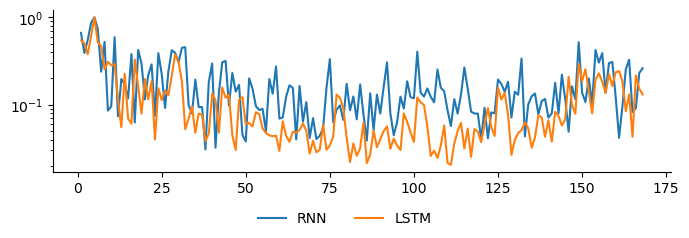

In [10]:
rnn = train_rec('rnn', X_[a], Y_[a], X_[b], Y_[b], hidden=48, epochs=40, lr=3e-3, bs=64, Str=S_[a], Sva=S_[b], patience=5)
fig, ax = plt.subplots(figsize=(7, 2.4)); ids = np.where(c)[0][:200]
for name, m in [('RNN', rnn), ('LSTM', lstm)]:
    xx = torch.tensor(X_[ids], requires_grad=True); m(xx, torch.tensor(S_[ids]))[:, 12].sum().backward()
    g = xx.grad[:, :, :24].abs().mean(0).numpy().reshape(-1)[::-1]; ax.semilogy(np.arange(1, 169), g / g.max(), label=name)
fig.legend(loc='lower center', ncol=2); fig.tight_layout(rect=(0, .1, 1, 1)); plt.show()